In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle

In [2]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

In [3]:
# load the dataset
df = pd.read_csv("spam.csv")
df.head()

,label,message
0,ham,I am making tea. Would you like some?
1,ham,Don't forget to bring your charger tomorrow.
2,ham,Let me know when you arrive safely.
3,spam,You have been awarded a cash bonus. Reply CLAIM.
4,spam,Free coupon available. Click to redeem before ...


In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)
print("\nLabel distribution:")
print(df["label"].value_counts())

Dataset shape: (100, 2)

Column names:
Index(['label', 'message'], dtype='str')

Label distribution:
label
ham     50
spam    50
Name: count, dtype: int64


In [5]:
# Clean and encode dataset
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

# Keep valid lebels and non-empty
df = df[
  df["label"].isin(["ham","spam"]) & df["message"].ne("")
].copy()

# Remoce duplicate examples
df = df.drop_duplicates(
  subset=["label","message"]
).reset_index(drop=True)

# Encode target values
df["target"] = df["label"].map({
  "ham":0,
  "spam":1
}).astype("int32")

df.head()

,label,message,target
0,ham,I am making tea. Would you like some?,0
1,ham,Don't forget to bring your charger tomorrow.,0
2,ham,Let me know when you arrive safely.,0
3,spam,You have been awarded a cash bonus. Reply CLAIM.,1
4,spam,Free coupon available. Click to redeem before ...,1


In [6]:
# Separate input and output
X = df["message"]
y = df["target"]

print("Input Message")
print(X.head())

print("\nTarget labels")
print(y.head())

Input Message
0                I am making tea. Would you like some?
1         Don't forget to bring your charger tomorrow.
2                  Let me know when you arrive safely.
3     You have been awarded a cash bonus. Reply CLAIM.
4    Free coupon available. Click to redeem before ...
Name: message, dtype: str

Target labels
0    0
1    0
2    0
3    1
4    1
Name: target, dtype: int32


In [7]:
# Split training and testing data
if len(df) < 10:
  raise ValueError(
    "Please provide at least 10 labeled messages"
  )
  
if y.nunique() != 2 or y.value_counts().min() < 2:
  raise ValueError(
    "Both ham and span atleast 2 examples"
  )
  
X_train,X_test,y_train,y_test = train_test_split(
  X,
  y,
  test_size = 0.25,
  random_state = 42,
  stratify = y
)

print("Training messages:",len(X_train))
print("Testing messages:",len(X_test))

Training messages: 75
Testing messages: 25


In [8]:
# Convert text into vectors
vectorizer = TfidfVectorizer(
  lowercase=True,
  strip_accents="unicode",
  ngram_range=(1,2),
  max_features=3000,
  sublinear_tf=True
)

# Learn vocabulary from train data only
X_train_vectorized = vectorizer.fit_transform(
  X_train
).toarray().astype(np.float32)

# Apply the same transformer to test data

X_test_vectorized = vectorizer.transform(
  X_test
).toarray().astype(np.float32)

print("Training feature shape:",X_train_vectorized.shape)
print("Testing feature shape:",X_test_vectorized.shape)

Training feature shape: (75, 762)
Testing feature shape: (25, 762)


In [9]:
# Build the ANN model
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
  tf.keras.layers.Input(
    shape=(X_train_vectorized.shape[1],)
  ),
  tf.keras.layers.Dense(
  64,
  activation="relu"
),
tf.keras.layers.Dropout(0.2),
tf.keras.layers.Dense(
  64,
  activation="relu"
),
tf.keras.layers.Dropout(0.2),
tf.keras.layers.Dense(
  1,
  activation="sigmoid"
)
])

model.compile(
  optimizer="adam",
  loss="binary_crossentropy",
  metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        48,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,057 (207.25 KB)

 Trainable params: 53,057 (207.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Train the model

early_stopping = tf.keras.callbacks.EarlyStopping(
  monitor="val_loss",
  patience=10,
  restore_best_weights=True
)

history = model.fit(
  X_train_vectorized,
  y_train.to_numpy(dtype=np.float32),
  validation_split=0.2,
  epochs=100,
  batch_size=8,
  callbacks=[early_stopping],
  verbose = 1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.4833 - loss: 0.6934 - val_accuracy: 0.5333 - val_loss: 0.6963
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7500 - loss: 0.6824 - val_accuracy: 0.4000 - val_loss: 0.6963
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9333 - loss: 0.6699 - val_accuracy: 0.4667 - val_loss: 0.6957
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9333 - loss: 0.6597 - val_accuracy: 0.4667 - val_loss: 0.6941
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9667 - loss: 0.6357 - val_accuracy: 0.4667 - val_loss: 0.6900
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9833 - loss: 0.6123 - val_accuracy: 0.5333 - val_loss: 0.6824
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9833 - loss: 0.5762 - val_accuracy: 0.6667 - val_loss: 0.6706
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.5159 - val_accuracy: 0.6667 - val_loss:

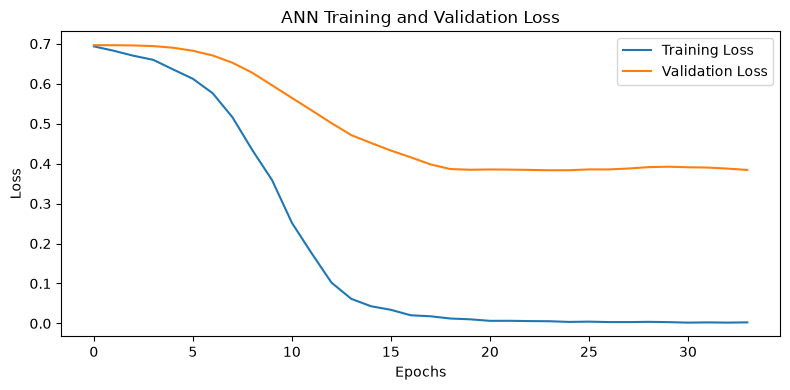

In [12]:
# Visualize training loss

plt.figure(figsize=(8,4))
plt.plot(
  history.history["loss"],
  label="Training Loss"
)

plt.plot(
  history.history["val_loss"],
  label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Evaluate the model
y_test_np = y_test.to_numpy(dtype=np.int32)
probabilities = model.predict(
  X_test_vectorized,
  verbose = 0
).ravel()

y_pred = (probabilities >= 0.5).astype(int)

print(
  classification_report(
    y_test_np,
    y_pred,
    labels=[0,1],
    target_names=["Ham","Spam"],
    zero_division=0
  )
)

              precision    recall  f1-score   support

         Ham       0.92      0.92      0.92        13
        Spam       0.92      0.92      0.92        12

    accuracy                           0.92        25
   macro avg       0.92      0.92      0.92        25
weighted avg       0.92      0.92      0.92        25



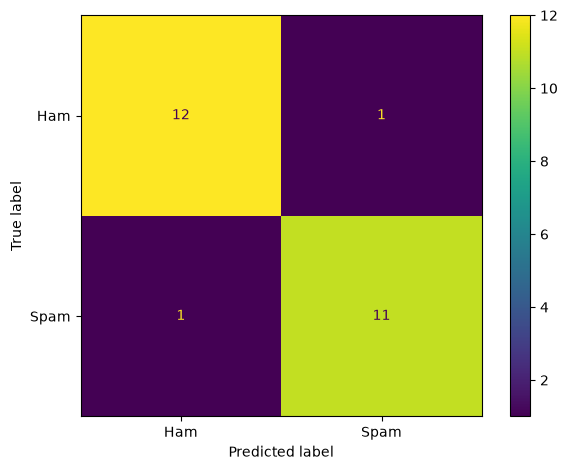

In [14]:
# Plot the confusion
cm = confusion_matrix(
  y_test_np,
  y_pred,
  labels=[0,1]
)

display_matrix = ConfusionMatrixDisplay(
  confusion_matrix=cm,
  display_labels=["Ham","Spam"]
)

display_matrix.plot()
plt.tight_layout()
plt.show()

In [15]:
# Save the model
model.save("ann_spam_model.keras")
with open("tfidf_vectorizer.pkl","wb") as file:
  pickle.dump(vectorizer,file)
  
print("ANN model saved successfully")
print("TF-IDF vectorizer saved successfully")


ANN model saved successfully
TF-IDF vectorizer saved successfully
